# **Collision Avoidance for Satellite**
## **1. Satellite location in the orbit is not known with accuracy, can we improve that?**
## **2. Can we use the trajectory information to predict if a satellite is going to collide with another?**

**Course:** 06-623 — Mathematical Modeling of Chemical Engineering Processes. 

**Instructor:** Prof. Hamish Gordon

**Team Members:** Gayatri Moghe, Madhav Agarwal, Abhinav Raghuvanshi

Lower earth orbit is getting more and more crowded with lots of satellites, it is becoming increasingly difficult to keep track of each of them. There is something called *TLE (Two-Line Element set)* data, that describes a satellite's orbital parameters at a specific moment. There are softwares that utilise this TLE data and orbit propagation algorithm called *SGP4* to calculate real-time satellite positions.

But we notice that these algorithms are not that good, when we compared these predictions with the actual satellite GPS data (which we treat as ground truth) we see that there are huge errors in the predicted trajectory and the actual trajectory that the satellite took, and because of that it becomes very difficult to predict if two satellites are about to collide. so we tried to fix it.

### How did we do it?
Whenever these algorithms run they have some error in their prediction. We track these errors from the past data and apply corrections accordingly in the future. We noticed that this significantly reduced the prediction error of SGP4 and the collision probabilities come out significantly more accurate too.


Main results and the essential equations are in the main sections. Detailed
mathematics and numerical checks are in the **appendix**.


# **How to run this notebook**

1. Open this notebook in Google Colab.
2. Choose **Runtime → Run all**. A standard **CPU** runtime is sufficient.
3. That's all

Source code is available at `https://github.com/abhinavr11/satellite-collision-avoidance`, branch
**main**, this colab clones that repo for some code that's in the repo.

In [1]:
# @title Get the project from GitHub
from pathlib import Path
import os, subprocess, sys

GITHUB_URL = "https://github.com/abhinavr11/satellite-collision-avoidance.git"
BRANCH = "main"
# Environment overrides are used only by automated local validation.
clone_url = os.environ.get("SATELLITE_DEMO_REPO_URL", GITHUB_URL)
workspace = Path(os.environ.get("SATELLITE_DEMO_WORKSPACE", "/content" if Path("/content").exists() else str(Path.cwd())))
PROJECT = workspace / "satellite-collision-avoidance"
if not (PROJECT / ".git").is_dir():
    workspace.mkdir(parents=True, exist_ok=True)
    cloned = subprocess.run(["git", "clone", "--depth", "1", "--branch", BRANCH, clone_url, str(PROJECT)],
                            text=True, capture_output=True)
    if cloned.returncode:
        raise RuntimeError("The repository could not be cloned. Push the notebook/data first and check repository access.\n" + cloned.stderr)
BUNDLE = PROJECT / "datasets" / "swarm_ac_shifted_v1"
if not (BUNDLE / "encounter.json").is_file():
    raise RuntimeError("This checkout does not contain the shifted dataset. Push the updated main branch and start a fresh runtime.")
sys.path.insert(0, str(PROJECT))
COMMIT = subprocess.check_output(["git", "-C", str(PROJECT), "rev-parse", "HEAD"], text=True).strip()
LOCAL_VALIDATION = clone_url != GITHUB_URL
print("Project ready: main branch; repository-contained shifted data found.")
print("Source:", "isolated local validation clone" if LOCAL_VALIDATION else GITHUB_URL)
if not LOCAL_VALIDATION:
    print("Commit:", COMMIT)


Project ready: main branch; repository-contained shifted data found.
Source: isolated local validation clone


In [2]:
# @title Prepare the numerical libraries
import importlib.util, importlib.metadata, platform
packages = {"numpy": "numpy", "scipy": "scipy", "matplotlib": "matplotlib", "astropy": "astropy", "sgp4": "sgp4"}
missing = [distribution for module, distribution in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "-r", str(PROJECT / "requirements-colab.txt")], check=True)
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown, Image
print("Python", platform.python_version())
for distribution in packages.values():
    print(distribution, importlib.metadata.version(distribution))
print("Libraries ready. No large source collection will be downloaded.")


Python 3.12.14
numpy 2.3.5
scipy 1.18.1
matplotlib 3.11.2
astropy 8.0.2
sgp4 2.27
Libraries ready. No large source collection will be downloaded.


In [ ]:
# @title Presentation helpers and demonstration settings
import csv, html, io, json
from datetime import datetime, timedelta
from collision_probability.data import SATELLITES, load_encounter, fingerprint
from collision_probability.encounter_forecast import METHODS, limit_encounter_end, ForecastTrajectories, evaluate_encounter_model
from collision_probability.window_selection import select_balanced_window
from collision_probability.confidence import fit_confident_prefix, candidate_correction
from collision_probability.evaluation import binary_scores
from collision_probability.probability import closest_approach
from experiments.collision_probability.run_experiment import evaluate_encounter, reference_outcome

CONFIDENCE_THRESHOLD = 0.99
RADIUS_A_M, RADIUS_C_M = 5.0, 5.0
COMBINED_RADIUS_M = RADIUS_A_M + RADIUS_C_M
MONTE_CARLO_SAMPLES = 1_000_000
RUN_DIR = PROJECT / "demo_outputs"
RUN_DIR.mkdir(exist_ok=True)
METHOD_NAMES = dict(zip(METHODS, ["SGP4: frozen error budget", "Gated correction: projected error budget", "SGP4: projected error budget"]))
COLORS = dict(zip(METHODS, ["#bd6036", "#226ca5", "#7954a1"]))

def table(headers, rows):
    header = "".join("<th>" + html.escape(str(value)) + "</th>" for value in headers)
    body = "".join("<tr>" + "".join("<td>" + html.escape(str(value)) + "</td>" for value in row) + "</tr>" for row in rows)
    display(HTML('<style>.demo-table{border-collapse:collapse;font-size:14px;margin:12px 0}.demo-table th,.demo-table td{border:1px solid #ccd5dd;padding:8px 12px;text-align:left}.demo-table th{background:#e9f1f8}.demo-table tr:nth-child(even){background:#f6f8fa}</style><table class="demo-table"><thead><tr>' + header + '</tr></thead><tbody>' + body + '</tbody></table>'))

def show_plot(figure, filename):
    figure.savefig(RUN_DIR / filename, dpi=150, bbox_inches="tight")
    buffer = io.BytesIO()
    figure.savefig(buffer, format="png", dpi=130, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(figure)

def utc(seconds):
    center = datetime.fromisoformat(metadata["synthetic_center_utc"].replace("Z", "+00:00"))
    return (center + timedelta(seconds=float(seconds))).isoformat(timespec="seconds")

print("Assumptions: 5 m radius per satellite; 10 m combined collision distance; 99% conditional correction gate.")


Assumptions: 5 m radius per object; 10 m combined collision distance; 99% conditional correction gate.


# **The data:**

For each satellite we have the real GPS data which tells us where it actually was and SGP4 predicted data which is what we shall be working with:

- A processed GPS-based **precise reference orbit**, treated as ground truth
  for this demonstration.

# **The split:**

We split one trajectory into training and testing. Training part of the trajectory is used to calculate errors and variances, which make the predictions on the test trajectory better. For example - if a trajectory is 10 minutes long, we use 7 mins as training and 
3 mins as testing.

In [ ]:
# @title Load and verify the single shifted dataset
metadata, original_states = load_encounter(BUNDLE)
original_times = original_states["sgp4", "Swarm-A"]["t"]
rows = []
for obj in metadata["objects"]:
    rows.append([obj["satellite"], obj["norad_id"], obj["source_center_utc"],
                 metadata["synthetic_center_utc"], f'{obj["source_to_synthetic_shift_seconds"]:,.6f} s'])
table(["Satellite", "NORAD ID", "Original reference time", "Shared crossing time", "Time shift"], rows)
print(f"Verified {len(original_times):,} samples per satellite per trajectory: two hours at one-second spacing.")
print("All four inputs share exactly the same synthetic timestamps. File checksums passed.")
print("Only datasets/swarm_ac_shifted_v1 is used below.")


# **Deciding the training and testing windows**

Imagine we have a 10 min trajectory, of which first 7 mins are used to calculate the corrections parameters and then those help in predicting *more accurate* trajectories for the next 3 mins. Now if we keep reducing the size of our training dataset, we notice that there is a continuous drop in the prediction accuracy, which is fairly intuitive since we now analyze errors of a very short interval and try to correct a larger interval trajectory based on that very small potentially biased data. So it is important to find the best split.


> **Forecast clock**
>
> $$
> \boxed{h = (t-t_{\mathrm{cutoff}})/3600}
> $$
>
> Here $h$ is hours from the end of training. Test reference positions are
> reserved for evaluation; they cannot choose the split or correction.



In [5]:
# @title Choose the forecast window from training-only validation
selection = select_balanced_window(original_states, threshold=CONFIDENCE_THRESHOLD)
cutoff = float(selection["training_cutoff_seconds"])
test_end = float(selection["test_end_seconds"])
states, unused_samples = limit_encounter_end(original_states, test_end)
time_grid = states["sgp4", "Swarm-A"]["t"]
training_mask, test_mask = time_grid <= cutoff, time_grid > cutoff
table(["Part", "Start, UTC", "End, UTC", "Samples per satellite"], [
    ["Available training history", utc(time_grid[training_mask][0]), utc(cutoff), int(training_mask.sum())],
    ["Held-out test", utc(time_grid[test_mask][0]), utc(test_end), int(test_mask.sum())]])
print(f"Selected {abs(cutoff)/60:g}-minute lead and {(test_end-cutoff)/60:g}-minute test.")
print(f"Selection used reference data only through {utc(selection['selection_reference_cutoff_seconds'])}.")
print(f"{unused_samples:,} later source timestamps are unused. No candidate test Pc was used to choose this window.")


Part,"Start, UTC","End, UTC",Samples per satellite
Available training history,2025-01-30T19:54:01+00:00,2025-01-30T20:51:01+00:00,3421
Held-out test,2025-01-30T20:51:02+00:00,2025-01-30T20:57:01+00:00,360


Selected 3-minute lead and 6-minute test.
Selection used reference data only through 2025-01-30T20:48:01+00:00.
3,420 later source timestamps are unused. No candidate test Pc was used to choose this window.


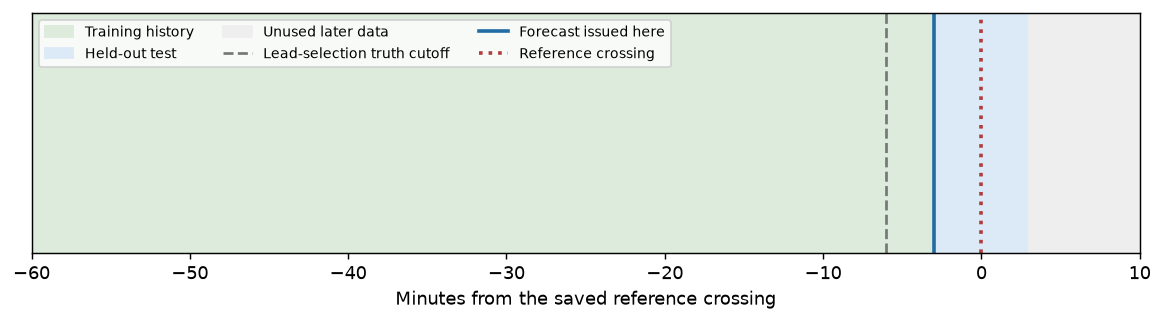

In [6]:
# @title See the chronological train/test split
fig, ax = plt.subplots(figsize=(11, 2.4))
ax.axvspan(-60, cutoff/60, color="#dcebdc", label="Training history")
ax.axvspan(cutoff/60, test_end/60, color="#dceaf7", label="Held-out test")
ax.axvspan(test_end/60, 10, color="#eeeeee", label="Unused later data")
ax.axvline(selection["selection_reference_cutoff_seconds"]/60, color="#777777", linestyle="--", label="Lead-selection truth cutoff")
ax.axvline(cutoff/60, color="#226ca5", linewidth=2, label="Forecast issued here")
ax.axvline(0, color="#b23b3b", linestyle=":", linewidth=2, label="Reference crossing")
ax.set(xlim=(-60, 10), ylim=(0, 1), yticks=[], xlabel="Minutes from the saved reference crossing")
ax.legend(loc="upper left", ncol=3, fontsize=8)
show_plot(fig, "timeline.png")


# **Our First major contribution : More accurate trajectories than known SOTA algorithm (SGP4)**
### **Observe mean errors and variances in training data -> Take SGP4 predictions -> Apply corrections based on those errors and variances -> Get better trajectories**

We subtract the predicted position from the reference position, then express
the error in the orbit's **radial, along-track and normal (RTN)** directions.

> **Observed training error**
>
> $$\boxed{\mathbf e_{RTN}(t)=\mathbf U_{ref}(t)^T
>       [\mathbf r_{ref}(t)-\mathbf r_{SGP4}(t)]}$$

A mean error describes a systematic offset. A covariance describes the
spread left after subtracting that mean. Within a training bin:

> **Learn bias and covariance from earlier errors**
>
> $$\boxed{\hat{\boldsymbol\mu}=\frac1K\sum_k\mathbf e_k,\qquad
> \hat{\mathbf P}=\frac1{K-1}\sum_k(\mathbf e_k-\hat{\boldsymbol\mu})
> (\mathbf e_k-\hat{\boldsymbol\mu})^T}$$

We fit a quadratic for the mean
and standard deviation in each direction:

> **Forecast error model**
>
> $$\boxed{\mu_j(h)=c_{j0}+c_{j1}h+c_{j2}h^2,
> \qquad \sigma_j(h)=s_{j0}+s_{j1}h+s_{j2}h^2}$$
>
> $$\boxed{\mathbf P_{RTN}(h)=\mathbf D(h)\boldsymbol\Gamma\mathbf D(h),
> \quad\mathbf D=\operatorname{diag}(\sigma_R,\sigma_T,\sigma_N)}$$

$\Gamma$ records how the three directional errors vary together. The fitted
spreads remain positive and nondecreasing for future lead times. The
appendix explains the likelihood fit, coordinate shift and covariance.


In [7]:
# @title Fit the recent quadratics and freeze the correction policy
models, training_errors, training_mask, test_mask, gates = fit_confident_prefix(
    states, cutoff, test_end, CONFIDENCE_THRESHOLD,
    folds=selection["final_rolling_validation_folds"])
curves = ForecastTrajectories(states, models, cutoff, gates, covariance_mode="second_moment")
rows = []
for name in SATELLITES:
    gate = gates[name]
    rows.append([name, f'{gate["selected_window_seconds"]/60:g} min',
                 f'{100*gate["minimum_test_horizon_model_confidence"]:.6f}%',
                 "Apply" if gate["apply_correction"] else "Withhold"])
table(["Satellite", "Selected recent fitting window", "Minimum conditional model confidence", "Frozen decision"], rows)
print("Window choice, covariance calibration and gate decisions were made using training data only.")


Satellite,Selected recent fitting window,Minimum conditional model confidence,Frozen decision
Swarm-A,5 min,100.000000%,Apply
Swarm-C,5 min,100.000000%,Apply


Window choice, covariance calibration and gate decisions were made using training data only.


## **Apply a correction only when the model is very confident**

Noisy directions are corrected less aggressively. A correction must pass a
**99% conditional model-confidence threshold** and rolling position checks
inside training. Its apply/withhold decision stays fixed throughout test.

> **Accepted position correction**
>
> $$\boxed{d_j=\frac{\mu_j^2}{\mu_j^2+P_{jj}}\mu_j,
> \qquad\mathbf m(t)=\mathbf r_{SGP4}(t)+\mathbf U_{pred}(t)\mathbf d(t)}$$
>
> $$\boxed{p_{help}=\Phi\!\left(
> \frac{\boldsymbol\mu^T\mathbf d-\tfrac12\|\mathbf d\|^2}
> {\sqrt{\mathbf d^T\mathbf P\mathbf d}}\right)\ge0.99}$$

If the gate fails, $\mathbf d=0$ and the original SGP4 trajectory is kept.
**Confidence that a correction helps is not collision probability.**
The 99% number is conditional on the fitted Gaussian error model; it is
not a demonstrated 99% empirical guarantee.

Rolling forecast errors inside training also inflate the fitted spreads.
This prevents a very tight curve fit from automatically being treated as
highly reliable future uncertainty.


In [8]:
# @title Inspect the error projected to the saved crossing
rows = []
for name in SATELLITES:
    mu, covariance = evaluate_encounter_model(models[name], -cutoff)
    correction, confidence = candidate_correction(mu, covariance)
    if not gates[name]["apply_correction"]:
        correction = np.zeros(3)
    rows.append([name, np.array2string(mu, precision=2),
                 np.array2string(np.sqrt(np.diag(covariance)), precision=2),
                 np.array2string(correction, precision=2)])
table(["Satellite", "Projected mean error R,T,N (m)", "Projected sigma R,T,N (m)", "Applied correction R,T,N (m)"], rows)


Satellite,"Projected mean error R,T,N (m)","Projected sigma R,T,N (m)","Applied correction R,T,N (m)"
Swarm-A,[ 47.73 -174.56 257.93],[ 7.12 21.97 8.72],[ 46.69 -171.84 257.63]
Swarm-C,[ 101.78 -266.57 -181.8 ],[1.1 1.06 5.11],[ 101.77 -266.57 -181.65]


## **Now reveal the held-out reference positions: did we improve them?**

This is the first time test reference positions are used to score position
accuracy. They do not change the model or the gate afterward.

> **Position error to compare**
>
> $$\boxed{E_{raw}(t)=\|\mathbf r_{ref}-\mathbf r_{SGP4}\|,
> \quad E_{corr}(t)=\|\mathbf r_{ref}-\mathbf m\|}$$

Lower error means a forecast is closer to the reference trajectory. The
plot uses a logarithmic vertical scale so metre-level and hundred-metre
errors can be seen together.


Satellite,Raw error at crossing (m),Corrected error (m),Raw test RMSE (m),Corrected test RMSE (m),Improved samples,Worsened samples
Swarm-A,312.02,3.42,310.21,6.26,360,0
Swarm-C,336.64,2.07,336.31,3.49,360,0


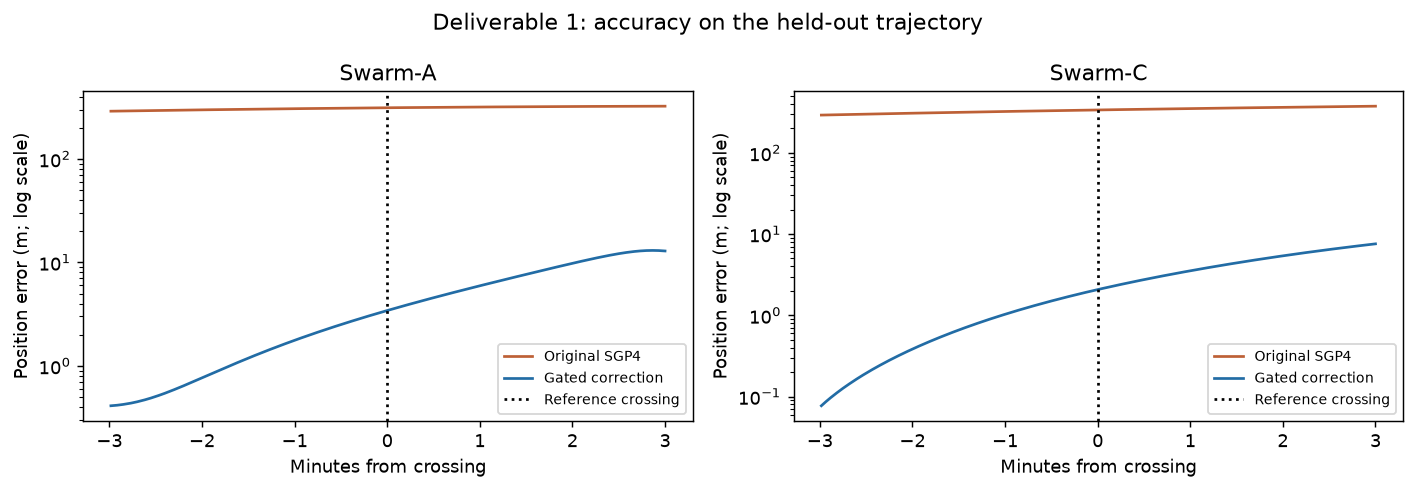

In [9]:
# @title Deliverable 1 results: measure every held-out position
position_results = {}
rows = []
for name in SATELLITES:
    reference = curves.position("reference", name, curves.times)
    raw = curves.position(METHODS[2], name, curves.times)
    corrected = curves.position(METHODS[1], name, curves.times)
    before = np.linalg.norm(raw-reference, axis=1)
    after = np.linalg.norm(corrected-reference, axis=1)
    changed = np.linalg.norm(corrected-raw, axis=1) > 1e-8
    improved = int(np.count_nonzero(changed & (after < before-1e-8)))
    worsened = int(np.count_nonzero(changed & (after > before+1e-8)))
    center_raw = float(np.linalg.norm(curves.position(METHODS[2], name, 0)-curves.position("reference", name, 0)))
    center_corrected = float(np.linalg.norm(curves.position(METHODS[1], name, 0)-curves.position("reference", name, 0)))
    position_results[name] = {"raw_rmse_m": float(np.sqrt(np.mean(before**2))),
                              "corrected_rmse_m": float(np.sqrt(np.mean(after**2))),
                              "changed_samples": int(changed.sum()), "improved_samples": improved,
                              "worsened_samples": worsened,
                              "raw_error_at_crossing_m": center_raw,
                              "corrected_error_at_crossing_m": center_corrected}
    rows.append([name, f'{center_raw:.2f}', f'{center_corrected:.2f}',
                 f'{position_results[name]["raw_rmse_m"]:.2f}', f'{position_results[name]["corrected_rmse_m"]:.2f}',
                 improved, worsened])
table(["Satellite", "Raw error at crossing (m)", "Corrected error (m)", "Raw test RMSE (m)", "Corrected test RMSE (m)", "Improved samples", "Worsened samples"], rows)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, name in zip(axes, SATELLITES):
    reference = curves.position("reference", name, curves.times)
    for method, label, color in [(METHODS[2], "Original SGP4", "#bd6036"), (METHODS[1], "Gated correction", "#226ca5")]:
        error = np.linalg.norm(curves.position(method, name, curves.times)-reference, axis=1)
        ax.semilogy(curves.times/60, error, label=label, color=color)
    ax.axvline(0, color="black", linestyle=":", label="Reference crossing")
    ax.set(title=name, xlabel="Minutes from crossing", ylabel="Position error (m; log scale)")
    ax.legend(fontsize=8)
fig.suptitle("Deliverable 1: accuracy on the held-out trajectory")
fig.tight_layout()
show_plot(fig, "position_accuracy.png")


## **See the actual and predicted paths**

This close-up shows both satellites around the shared crossing, with the
reference, original SGP4 and corrected paths in the **same spatial frame**.
We subtract one fixed reference position to make metre-scale differences
visible. The reference paths are used here only for the evaluation plot.
The corrected and reference curves nearly overlap; the error table above
resolves their remaining metre-level differences.


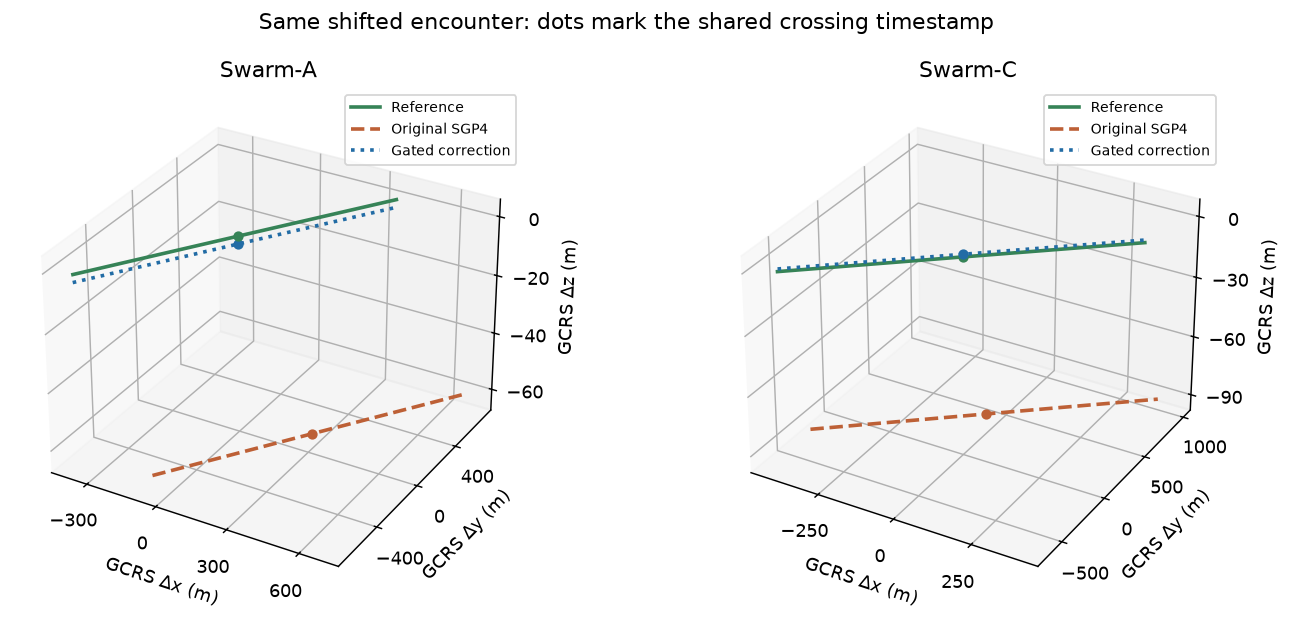

In [10]:
# @title Compare the three trajectories for both satellites
from matplotlib.ticker import MaxNLocator
near_times = np.linspace(-0.1, 0.1, 101)
origin = curves.position("reference", "Swarm-A", 0.0)
fig = plt.figure(figsize=(11, 4.8))
for panel, name in enumerate(SATELLITES, start=1):
    ax = fig.add_subplot(1, 2, panel, projection="3d")
    for kind, label, color, style in [
        ("reference", "Reference", "#368357", "-"),
        (METHODS[2], "Original SGP4", "#bd6036", "--"),
        (METHODS[1], "Gated correction", "#226ca5", ":")]:
        path = curves.position(kind, name, near_times)-origin
        ax.plot(*path.T, label=label, color=color, linestyle=style, linewidth=2)
        at_crossing = curves.position(kind, name, 0.0)-origin
        ax.scatter(*at_crossing, color=color, s=22)
    ax.set(title=name, xlabel="GCRS Δx (m)", ylabel="GCRS Δy (m)", zlabel="GCRS Δz (m)")
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.set_major_locator(MaxNLocator(nbins=4))
    ax.legend(fontsize=8)
fig.suptitle("Same shifted encounter: dots mark the shared crossing timestamp")
fig.tight_layout()
show_plot(fig, "trajectory_closeup.png")


# **Our second contribution— Now that we have more accurate trajectories can we calculate more accurate collision probabilities**
### **Find the corrected coordinates of the closest approach of two satellites from their trajectories ->  Use the projected mean error and the variances at those coordinates to calculate the probability of collision**

Approximate each satellite as a sphere. Our illustrative radii are **5 m
each**, so the combined collision distance is **10 m**. These are assumptions,
not measured spacecraft dimensions.

> **Binary reference outcome**
>
> $$\boxed{R=R_A+R_C,\qquad
> y=\mathbf1\!\left[\min_t\|\mathbf r_{A,ref}(t)-\mathbf r_{C,ref}(t)\|\le R\right]}$$

Treating the reference paths as exact, the outcome is collision ($y=1$) or
no collision ($y=0$).
The prediction models still have uncertainty, so their collision forecasts
are probabilities.


In [11]:
# @title Compute the reference collision label from the same shifted data
truth = reference_outcome(curves, metadata, COMBINED_RADIUS_M, 60.0)
table(["Reference quantity", "Value"], [
    ["Closest separation", f'{truth["closest_approach"]["miss_distance_m"]:.6f} m'],
    ["Assumed radius of each satellite", f'{RADIUS_A_M:g} m and {RADIUS_C_M:g} m'],
    ["Combined collision distance", f'{COMBINED_RADIUS_M:g} m'],
    ["Reference outcome", truth["outcome"]],
    ["Binary label y", truth["collision_label"]]])
print("This label describes the constructed encounter, not a historical collision report.")


Reference quantity,Value
Closest separation,0.286440 m
Assumed radius of each satellite,5 m and 5 m
Combined collision distance,10 m
Reference outcome,collision
Binary label y,1


This label describes the constructed encounter, not a historical collision report.


## **Turn relative uncertainty into collision probability**

Each prediction finds its own time of closest approach **inside the same
selected encounter**. We look in a plane perpendicular to relative motion:
the uncertain passing location is a two-dimensional Gaussian.

> **Relative distribution and encounter-plane projection**
>
> $$\boxed{\bar{\mathbf r}_{rel}=\mathbf m_A-\mathbf m_C,
> \quad \mathbf S_{rel}=\mathbf S_A+\mathbf S_C}$$
>
> $$\boxed{\mathbf b=\mathbf Q^T\bar{\mathbf r}_{rel},
> \qquad\mathbf C=\mathbf Q^T\mathbf S_{rel}\mathbf Q}$$

Where $\mathbf m_A$ and $\mathbf m_C$ are bias corrected locations and $\mathbf S_A$ and $ \mathbf S_C$ are covariances of the satellites A and C respectively. $Q$ contains two perpendicular unit axes in that plane. Collision occurs
when the passing location lies inside the circle of radius $R$:

> **Main collision-probability result**
>
> $$\boxed{P_c=\iint_{x^2+y^2\le R^2}
> \frac{\exp[-\tfrac12(\mathbf z-\mathbf b)^T\mathbf C^{-1}(\mathbf z-\mathbf b)]}
> {2\pi\sqrt{\det\mathbf C}}\,dx\,dy}$$

The code evaluates this integral with converged Gauss–Legendre quadrature.
A seeded Monte Carlo simulation is an independent numerical cross-check,
not a collection of observed collisions. A short-encounter diagnostic checks
local curvature and covariance changes.


In [12]:
# @title Compute collision forecasts for the three techniques
results = {}
outcome_scores = {}
for method in METHODS:
    result = evaluate_encounter(curves, method, metadata, COMBINED_RADIUS_M,
                                MONTE_CARLO_SAMPLES, 60.0)
    results[method] = result
    outcome_scores[method] = binary_scores(result["quadrature"]["pc"], truth["collision_label"], result["quadrature"]["log_pc"])
rows = []
for method in METHODS:
    result = results[method]
    rows.append([METHOD_NAMES[method], f'{result["closest_approach"]["miss_distance_m"]:.3f}',
                 f'{100*result["quadrature"]["pc"]:.4f}%',
                 f'{result["closest_approach"]["elapsed_seconds"]-cutoff:.3f}',
                 f'{outcome_scores[method]["log_loss"]:.4f}'])
table(["Forecast", "Predicted closest separation (m)", "Pc", "Lead to predicted closest approach (s)", "Log loss: lower is better"], rows)


Forecast,Predicted closest separation (m),Pc,Lead to predicted closest approach (s),Log loss: lower is better
SGP4: frozen error budget,107.794,1.1010%,181.735,4.5089
Gated correction: projected error budget,4.629,21.7413%,179.992,1.5260
SGP4: projected error budget,107.794,0.4832%,181.735,5.3326


## **Preventing a possible collision: SGP4 said 107.79 m will be the distance between the passing satellites → We said 4.63 m will be the closest distance between the satellites with correction and the actual data showed that indeed a collision was about to happen and the actual distance would have been 0.286 m**

> **Without correction: SGP4 predicts a closest separation of 107.79 m.**
> This is **larger than the 10 m combined collision distance**, so the
> uncorrected predicted paths indicate **a miss: no physical collision**.
> Both uncorrected methods have this same closest separation; changing
> the error budget alone does not move their trajectories.
>
> **With the gated correction: the predicted closest separation falls to
> 4.63 m.** This is **inside the 10 m collision distance**, so the corrected
> predicted paths indicate **a collision**.
>
> **Ground truth for this constructed case: 0.286 m closest separation.**
> The reference paths also indicate **a collision** under the same assumed
> radii. The correction therefore changes the predicted geometry from a
> **107.79 m miss** to a **4.63 m collision**, much closer to the reference
> encounter.

These numbers describe the bundled dataset with the default settings, at
each trajectory pair's own closest approach. **A miss of the uncorrected
mean paths does not mean zero collision probability:** once uncertainty
is included, their Pc values remain nonzero, as shown in the table above.


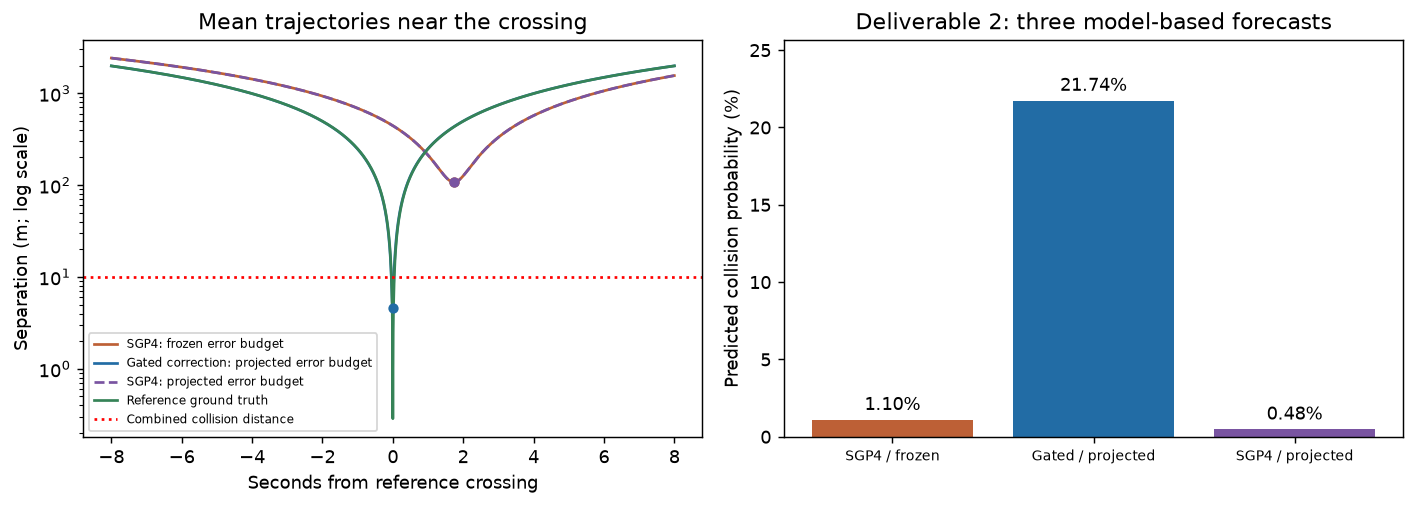

In [13]:
# @title See the encounter and the probability comparison
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
zoom_times = np.linspace(-8, 8, 1601)
for method in METHODS:
    axes[0].semilogy(zoom_times, np.linalg.norm(curves.relative(method, zoom_times), axis=1),
                      label=METHOD_NAMES[method], color=COLORS[method],
                      linestyle="--" if method == METHODS[2] else "-")
    closest = results[method]["closest_approach"]
    axes[0].scatter(closest["elapsed_seconds"], closest["miss_distance_m"], color=COLORS[method], s=22, zorder=5)
axes[0].semilogy(zoom_times, np.linalg.norm(curves.relative("reference", zoom_times), axis=1), color="#368357", label="Reference ground truth")
axes[0].axhline(COMBINED_RADIUS_M, color="red", linestyle=":", label="Combined collision distance")
axes[0].set(xlabel="Seconds from reference crossing", ylabel="Separation (m; log scale)", title="Mean trajectories near the crossing")
axes[0].legend(fontsize=6.5)
percent = [100*results[m]["quadrature"]["pc"] for m in METHODS]
bars = axes[1].bar(["SGP4 / frozen", "Gated / projected", "SGP4 / projected"], percent,
                   color=[COLORS[m] for m in METHODS])
axes[1].bar_label(bars, labels=[f'{p:.2f}%' for p in percent], padding=3)
axes[1].set(ylabel="Predicted collision probability (%)", title="Deliverable 2: three model-based forecasts",
            ylim=(0, max(percent)*1.18))
axes[1].tick_params(axis="x", labelsize=8)
fig.tight_layout()
show_plot(fig, "collision_comparison.png")


# **What have the two deliverables shown?**

**Deliverable 1:** We can audit whether each accepted correction actually
moved a held-out SGP4 position closer to its reference position.

**Deliverable 2:** We can compute collision probabilities from the corrected
and uncorrected predictions, state the uncertainty assumptions, and score
them against the **binary reference outcome**.

> **Evaluate the forecast against the outcome**
>
> $$\boxed{\text{Brier}=(P_c-y)^2,\qquad
> \text{log loss}=-y\log P_c-(1-y)\log(1-P_c)}$$

Lower scores are better. On this collision case a higher Pc scores better;
on a non-collision case a lower Pc scores better. **One constructed case
cannot establish general probability accuracy or calibration.** Improved
positions also do not guarantee improved Pc in every encounter.


In [14]:
# @title Summarize and save this run
winner = min(METHODS, key=lambda m: outcome_scores[m]["log_loss"])
rows = []
for name, value in position_results.items():
    rows.append([name, f'{value["raw_error_at_crossing_m"]:.2f} m → {value["corrected_error_at_crossing_m"]:.2f} m',
                 f'{value["improved_samples"]}/{len(curves.times)}', value["worsened_samples"]])
table(["Satellite", "Position error at the reference crossing", "Changed positions that improved", "Changed positions that worsened"], rows)
display(Markdown(f'**Lowest collision-forecast log loss on this case:** {METHOD_NAMES[winner]}.'))
run_summary = {"dataset_id": metadata["dataset_id"],
               "source": "local validation clone" if LOCAL_VALIDATION else COMMIT,
               "dataset_metadata_sha256": fingerprint(BUNDLE / "encounter.json"),
               "window_selection": selection, "confidence_threshold": CONFIDENCE_THRESHOLD,
               "radii_m": {"Swarm-A": RADIUS_A_M, "Swarm-C": RADIUS_C_M},
               "position_results": position_results, "ground_truth": truth,
               "collision_results": results, "outcome_scores": outcome_scores,
               "uncertainty_mode": "second_moment", "test_truth_used_for_model_selection": False}
(RUN_DIR / "notebook_results.json").write_text(json.dumps(run_summary, indent=2, allow_nan=False) + "\n")
with (RUN_DIR / "collision_forecasts.csv").open("w", newline="") as handle:
    writer = csv.writer(handle)
    writer.writerow(["method", "pc", "log_pc", "reference_label", "brier_score", "log_loss"])
    for method in METHODS:
        writer.writerow([method, results[method]["quadrature"]["pc"], results[method]["quadrature"]["log_pc"],
                         truth["collision_label"], outcome_scores[method]["brier_score"], outcome_scores[method]["log_loss"]])
print("Saved the figures, result tables and reproducibility information in demo_outputs/ inside the Colab clone.")


Satellite,Position error at the reference crossing,Changed positions that improved,Changed positions that worsened
Swarm-A,312.02 m → 3.42 m,360/360,0
Swarm-C,336.64 m → 2.07 m,360/360,0


**Lowest collision-forecast log loss on this case:** Gated correction: projected error budget.

Saved the figures, result tables and reproducibility information in demo_outputs/ inside the Colab clone.


# **Appendix — Mathematical details and checks**
## **A. Frames, time and the RTN basis**

SP3 epochs originally use GPS time; the selected products are 18 seconds
ahead of UTC. The data-preparation code converts native times to UTC,
interpolates the reference orbit, and converts IGS20/IGb20 terrestrial
coordinates (treated as ITRS here) into GCRS. SGP4's native TEME output is
transformed to GCRS at its original native epoch. Only then is C's timeline
relabelled. The notebook loads the prepared coordinates and does not repeat
the GPS/UTC subtraction.

With position $\mathbf r$ and velocity $\mathbf v$:
$$\hat R=\frac{\mathbf r}{\|\mathbf r\|},\quad
\hat N=\frac{\mathbf r\times\mathbf v}{\|\mathbf r\times\mathbf v\|},\quad
\hat T=\hat N\times\hat R,\quad \mathbf U=[\hat R\ \hat T\ \hat N].$$
Training errors use the **reference** RTN basis. Inference rotates the
learned correction and uncertainty with the **predicted** RTN basis, which
does not require future truth. Mean velocities for encounter geometry are
derivatives of the continuous mean-position curves, including correction.


## **B. Sample covariance and the quadratic fit**

For $K\ge2$ errors in a training bin:
$$\boldsymbol\mu=\frac1K\sum_k\mathbf e_k,\qquad
\mathbf P=\frac1{K-1}\sum_k(\mathbf e_k-\boldsymbol\mu)(\mathbf e_k-\boldsymbol\mu)^T.$$
This retains all three variances and all three cross-direction covariances.
Directional standard deviation is $\sigma_j=\sqrt{P_{jj}}$, not $P_{jj}$.

Each directional quadratic is fitted by minimizing the guide's marginal
Gaussian negative log likelihood:
$$\min_{c,s}\sum_k\left[\log\sigma_j(x_k)
+\frac{(e_{k,j}-\mu_j(x_k))^2}{2\sigma_j(x_k)^2}\right].$$
Here $x$ is hours from the selected training-window start. Constraints are
$s_0>0$ and $s_1,s_2\ge0$. For fixed spreads, weighted least squares gives
the mean coefficients; bounded optimization fits the spreads.

Coefficients are translated to $h=0$ at the training cutoff. If the selected
training-window duration is $a$ hours:
$$c'_0=c_0+c_1a+c_2a^2,\qquad c'_1=c_1+2c_2a,\qquad c'_2=c_2.$$
The same translation applies to the spread quadratics.

Initially, $z_{k,j}=(e_{k,j}-\mu_j(x_k))/\sigma_j(x_k)$ gives a residual
correlation matrix. In the confidence-gated implementation, standardized
**rolling forecast errors inside training** calibrate its correlation and
inflate spreads by factors of at least one. This adds information about
extrapolation error while preserving positive, nondecreasing spread curves.
It does not fully quantify parameter uncertainty or produce independent
validation of covariance.


In [15]:
# @title Inspect the learned coefficients and correlation matrices
rows = []
for name in SATELLITES:
    for direction, c, s in zip(["R", "T", "N"], models[name]["mean_coefficients_about_cutoff"], models[name]["sigma_coefficients_about_cutoff"]):
        rows.append([name, direction, *[f'{v:.4g}' for v in c], *[f'{v:.4g}' for v in s]])
table(["Satellite", "Direction", "c0 (m)", "c1 (m/h)", "c2 (m/h²)", "s0 (m)", "s1 (m/h)", "s2 (m/h²)"], rows)
for name in SATELLITES:
    print(name, "correlation matrix Γ:")
    print(np.array2string(np.array(models[name]["correlation"]), precision=4))
    print("Training-backtest spread inflation:", np.array(models[name]["validation_spread_inflation_rtn"]).round(3))


Satellite,Direction,c0 (m),c1 (m/h),c2 (m/h²),s0 (m),s1 (m/h),s2 (m/h²)
Swarm-A,R,82.34,-621.3,-1418,3.289,58.97,353.8
Swarm-A,T,-138.7,-810.7,1891,8.873,201.5,1209
Swarm-A,N,239.9,448.7,-1756,8.72,0,0
Swarm-C,R,106.7,-76.1,-432.3,1.104,0,0
Swarm-C,T,-225.8,-860.5,895.5,0.4559,9.284,55.7
Swarm-C,N,-149.3,-722,1454,2.218,44.54,267.2


Swarm-A correlation matrix Γ:
[[ 1.      0.0554  0.0717]
 [ 0.0554  1.     -0.5486]
 [ 0.0717 -0.5486  1.    ]]
Training-backtest spread inflation: [ 45.402  52.789 268.633]
Swarm-C correlation matrix Γ:
[[ 1.     -0.3609  0.3063]
 [-0.3609  1.      0.1602]
 [ 0.3063  0.1602  1.    ]]
Training-backtest spread inflation: [64.715 36.442 64.647]


## **C. Why the confidence formula measures position improvement**

Let $\mathbf e$ be reference-minus-SGP4 error and $\mathbf d$ the proposed
correction. It helps when:
$$\|\mathbf e-\mathbf d\|^2<\|\mathbf e\|^2
\iff \mathbf e^T\mathbf d>\tfrac12\|\mathbf d\|^2.$$
For $\mathbf e\sim N(\boldsymbol\mu,\mathbf P)$, the scalar projection is:
$$\mathbf e^T\mathbf d\sim
N(\boldsymbol\mu^T\mathbf d,\mathbf d^T\mathbf P\mathbf d),$$
which gives the $\Phi$ expression in the main section.

Selection uses only training reference data through the earliest candidate
cutoff. For each proposed lead, earlier rolling forecast blocks test recent
fitting windows. The longest lead passing the predefined position-RMSE and
confidence conditions for both objects is selected, then models are refitted
at the actual forecast origin. Gates do not switch on or off in response to
observed test errors. The 99% condition is model-based; correlated samples
and reused exploratory cases prevent an independent empirical guarantee.


## **D. Why a second moment differs from covariance**

Write $\mathbf e=\boldsymbol\mu+\boldsymbol\epsilon$, with
$E[\boldsymbol\epsilon]=0$ and
$E[\boldsymbol\epsilon\boldsymbol\epsilon^T]=\mathbf P$. After correction:
$$E[(\mathbf e-\mathbf d)(\mathbf e-\mathbf d)^T]
=\mathbf P+(\boldsymbol\mu-\mathbf d)(\boldsymbol\mu-\mathbf d)^T.$$

The true centred covariance remains $P$. Assigning a **zero-mean Gaussian**
about an uncorrected or partly corrected prediction with the second moment
$S$ is an explicit approximation. It includes the remaining systematic error
in RMS width but does not reproduce the original biased distribution's mean.
This choice changes the uncertainty model as well as the mean-correction
comparison; it is not a way to establish calibration from attractive numbers.

The following controls keep only the centred residual covariance $P$ for all
forecasts. The mean trajectories, fitted models, gates and data are unchanged.


In [16]:
# @title Compare with the original residual-covariance-only controls
residual_curves = ForecastTrajectories(states, models, cutoff, gates, covariance_mode="residual")
residual_results = {}
rows = []
for method in METHODS:
    result = evaluate_encounter(residual_curves, method, metadata, COMBINED_RADIUS_M,
                                MONTE_CARLO_SAMPLES, 60.0)
    residual_results[method] = result
    rows.append([METHOD_NAMES[method], f'{100*results[method]["quadrature"]["pc"]:.6g}%',
                 f'{result["quadrature"]["pc"]:.6g}', f'{result["quadrature"]["log_pc"]:.4f}'])
table(["Forecast", "Main second-moment model Pc", "Residual-only Pc", "Residual-only log(Pc)"], rows)
print("A larger forecasting window alone does not make the raw probabilities moderate. The uncertainty assumption matters.")


Forecast,Main second-moment model Pc,Residual-only Pc,Residual-only log(Pc)
SGP4: frozen error budget,1.10101%,4.79577e-59,-134.2848
Gated correction: projected error budget,21.7413%,0.220276,-1.5129
SGP4: projected error budget,0.483154%,4.92305e-14,-30.6423


A larger forecasting window alone does not make the raw probabilities moderate. The uncertainty assumption matters.


## **E. Encounter plane, integration and numerical checks**

Closest approach is found separately for each mean trajectory:
$$t_c=\arg\min_t\|\mathbf m_A(t)-\mathbf m_C(t)\|.$$
The relative velocity is the derivative of that relative mean. Define
$\hat q_3=\mathbf v_{rel}/\|\mathbf v_{rel}\|$, choose a unit axis $\mathbf a$
away from parallel, and construct:
$$\hat q_1=\frac{\hat q_3\times\mathbf a}{\|\hat q_3\times\mathbf a\|},
\quad\hat q_2=\hat q_3\times\hat q_1,\quad \mathbf Q=[\hat q_1\ \hat q_2].$$
Independence gives $S_{rel}=S_A+S_C$ for the stated prediction model.
Correlated object errors would require cross-covariance terms.

Polar coordinates turn the Gaussian disk integral into:
$$P_c=\int_0^{2\pi}\int_0^R
p(\rho\cos\theta,\rho\sin\theta)\,\rho\,d\rho\,d\theta.$$
The Jacobian factor $\rho$ is essential. The implementation doubles
Gauss–Legendre radial/angular orders until the result stabilizes and checks
positive-definite covariance. Finite log probabilities are retained when the
probability itself underflows floating-point storage.

Direct Monte Carlo draws $\mathbf z\sim N(\mathbf b,\mathbf C)$ and counts
$\|\mathbf z\|\le R$. Rare events need many samples; zero hits cannot establish
zero probability. Local three-sigma duration, projected curvature, velocity
direction and covariance variation diagnose the short-encounter approximation.


In [17]:
# @title Review numerical convergence and Monte Carlo cross-checks
rows = []
for method in METHODS:
    result = results[method]
    last = result["quadrature"]["history"][-1]
    rows.append([METHOD_NAMES[method], result["quadrature"]["converged"],
                 f'{last["radial_order"]} / {last["angular_order"]}',
                 f'{100*result["monte_carlo"]["pc"]:.4f}%',
                 f'{result["monte_carlo"]["hits"]:,} / {result["monte_carlo"]["samples"]:,}',
                 result["short_encounter_diagnostic"]["supported"]])
table(["Forecast", "Quadrature converged", "Radial / angular order", "Monte Carlo Pc", "MC hits / samples", "Local short-encounter check"], rows)
assert all(result["quadrature"]["converged"] for result in results.values())
assert all(result["short_encounter_diagnostic"]["supported"] for result in results.values())
print("All checks passed for this run. These are numerical checks, not evidence of general probability calibration.")


Forecast,Quadrature converged,Radial / angular order,Monte Carlo Pc,MC hits / samples,Local short-encounter check
SGP4: frozen error budget,True,32 / 64,1.1135%,"11,135 / 1,000,000",True
Gated correction: projected error budget,True,32 / 64,21.7621%,"217,621 / 1,000,000",True
SGP4: projected error budget,True,32 / 64,0.4791%,"4,791 / 1,000,000",True


All checks passed for this run. These are numerical checks, not evidence of general probability calibration.


## **F. Interpretation, limits and reproducibility**

- Reference trajectories supply **binary outcomes**, not reference Pc values.
  Brier score and log loss evaluate the probability forecasts. One observed
  outcome cannot reveal a true underlying forecast probability.
- Both objects come from the same related spacecraft family. Independent
  prediction errors, Gaussian tails, illustrative physical radii and ignored
  reference error are assumptions. No avoidance maneuver is simulated.
- One-second samples are interpolated and correlated. Rolling blocks are
  parts of the same orbit, not independent encounters. This previously
  inspected case is exploratory rather than independent validation.
- All primary and control calculations in this notebook use the same
  repository-contained shifted data. No historical multi-satellite calibration
  dataset is mixed into either deliverable.
- The repository's [`Collision_Avoidance_Simple_Guide.md`](https://github.com/abhinavr11/satellite-collision-avoidance/blob/main/docs/Collision_Avoidance_Simple_Guide.md) provides the broader
  method. This notebook follows its error → bias/covariance → relative
  uncertainty → collision probability sequence, with the confidence gate
  and uncertainty-baseline assumptions stated explicitly.

**To reproduce this exact run:** retain the cloned source commit, the input
file hashes and `demo_outputs/notebook_results.json`. Library versions were
printed in the setup cell. The pinned locally tested environment is in
`requirements-lock.txt`; the notebook uses portable Colab requirements.
